# Human Factors: Supervision, Takeover and Misuse

**Module 07 · Runtime Assurance and Operations** · Notebook 3 of 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/07_Runtime_Assurance_and_Operations/03_human_factors_and_takeover.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [ODD and runtime monitoring](01_odd_and_runtime_monitoring.ipynb), [STPA](../03_Functional_Safety_ISO26262/05_stpa.ipynb); basic probability | SAE J3016 (2021), UN R157 (01 series), Reg. (EU) 2019/2144, ISO 21448:2022 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Distinguish the human roles of SAE J3016: the **Level 2 driver who supervises** and the **Level 3 fallback-ready user**, and state what each implies for system design.
2. Explain **automation complacency**, **mode confusion** and the **out-of-the-loop** problem, and connect each to a design requirement.
3. Use published take-over-time evidence correctly: what the meta-analysis of Zhang et al. (2019) shows, and why non-critical transitions take much longer (Eriksson & Stanton, 2017).
4. Fit a take-over-time **distribution** to published summary statistics and compute the **lead time required for 95 % successful takeovers**, with its uncertainty.
5. Simulate takeover outcomes against the **UN R157** transition demand and MRM timings, and size the transition demand for a planned event.
6. State the driver-monitoring requirements of UN R157 and the **DDAW/ADDW** timeline of Regulation (EU) 2019/2144.
7. Run a **foreseeable-misuse analysis** as an ISO 21448 work product, using the NHTSA Autopilot recall 23V-838 as a real case.

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D

In [2]:
# Setup
import json
import urllib.request
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq
from IPython.display import display

rng = np.random.default_rng(2026)
TODAY = date(2026, 10, 28)          # date of the last content review; status statements refer to it
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
OI = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
      "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "black": "#000000", "grey": "#999999"}
print(D.attribution("NHTSA SGO"))

Data: NHTSA Standing General Order 2021-01 crash reports, public US government data, https://www.nhtsa.gov/laws-regulations/standing-general-order-crash-reporting


**Data and licence.** This notebook uses (i) NHTSA Standing General Order crash reports for Level 2 systems (public US government data, loaded with `D.nhtsa_sgo("ADAS")`), (ii) the NHTSA recall record 23V-838 from the public NHTSA recalls API, and (iii) **published summary statistics** of take-over times (means and standard deviations per experimental condition) from three driving-simulator studies, as compiled in Table 1 of the systematic review by Liang, Calvert & van Lint (arXiv:2507.22262; published in *Human Factors*, 2026). No individual participant data are used. If the NHTSA sources cannot be reached, the notebook falls back to stored values and says so.

## 1. Who is responsible? SAE J3016 roles

| | **Level 2** (driver support) | **Level 3** (conditional automation) | **Level 4** (high automation) |
|---|---|---|---|
| Who performs the DDT while engaged | Driver and system share it: the system does sustained lateral **and** longitudinal control; the **driver performs the rest of the object and event detection and response (OEDR) and supervises** | ADS performs the entire DDT within its ODD | ADS performs the entire DDT within its ODD |
| Human role | **Driver**, at all times | **Fallback-ready user**: able to operate the vehicle and receptive to ADS-issued requests to intervene and to evident vehicle system failures | Passenger or user; no fallback role |
| Who performs the DDT fallback | Driver | Fallback-ready user, after a request to intervene (under UN R157 the ALKS performs an MRM if the user does not respond) | ADS |
| What monitoring of the human must ensure | **Supervision**: eyes on road, hands ready (engagement) | **Availability**: able to take over within the transition time | Not needed for safety |
| Typical failure | Complacency: supervision lapses while the system works well | Takeover too slow or of poor quality; misuse (sleep, leaving the seat) | – |

Two consequences shape everything below. At **Level 2** the human is part of the control loop at every moment, so a monitoring lapse is an immediate hazard. At **Level 3** the human is *not* in the loop while the ADS drives, so the safety question becomes whether the human can **re-enter** the loop in time, and what the system does if not.

## 2. Three human-automation problems

| Problem | Mechanism | Design consequence |
|---|---|---|
| **Automation complacency** (Parasuraman & Manzey, 2010) | When automation is reliable, attention to it decreases; failures that the human should catch are missed. Reliable automation makes the problem *worse*, not better | Do not rely on unaided supervision for Level 2; monitor engagement (DMS) and escalate; design the ODD so that the human is not asked to catch rare failures |
| **Mode confusion** (Sarter & Woods, 1995) | The human's belief about the automation mode differs from the actual mode, especially after indirect mode changes with weak feedback | Multimodal feedback on every mode change, no silent fall-back to a weaker mode (UN R157 §6.2.6), check hands-off after deactivation; see the screening in [STPA, Section 5.1](../03_Functional_Safety_ISO26262/05_stpa.ipynb) |
| **Out-of-the-loop** (Endsley & Kiris, 1995) | Without active control, situation awareness decays; on takeover, the human must first rebuild it, which costs time and quality | Lead times based on the slow tail of take-over times; graded transitions; reduce speed during the transition (UN R157 §5.4.3) |

Bainbridge's *Ironies of Automation* (1983) summarises the paradox: the more capable the automation, the less practised and the less attentive the human who is supposed to handle the situations the automation cannot.

## 3. Real-world evidence: supervision at Level 2

### 3.1 The Autopilot recall 23V-838

In December 2023 Tesla filed recall 23V-838 for Autosteer, its SAE Level 2 lane-centring feature. The defect was not a component failure: the recall describes the **driver-engagement controls** as possibly insufficient to prevent misuse. We read the record from NHTSA's public recalls API.

In [3]:
RECALL_FALLBACK = {   # retrieved from api.nhtsa.gov on 2026-10-28
    "NHTSACampaignNumber": "23V838000", "Manufacturer": "Tesla, Inc.", "ReportReceivedDate": "12/12/2023",
    "PotentialNumberofUnitsAffected": 2031220, "NHTSAActionNumber": "EA22002",
    "Summary": ("Tesla, Inc. (Tesla) is recalling 2012-2023 Model S, 2016-2023 Model X, 2017-2023 Model 3, and "
                "2020-2023 Model Y vehicles equipped with all versions of Autosteer leading up to the version(s) "
                "that contains the recall remedy.  In certain circumstances when Autosteer is engaged, the "
                "prominence and scope of the feature's controls may not be sufficient to prevent driver misuse of "
                "the SAE Level 2 advanced driver-assistance feature."),
    "Consequence": ("In certain circumstances when Autosteer is engaged, and the driver does not maintain "
                    "responsibility for vehicle operation and is unprepared to intervene as necessary or fails to "
                    "recognize when Autosteer is canceled or not engaged, there may be an increased risk of a crash."),
    "overTheAirUpdate": True,
}
try:
    url = "https://api.nhtsa.gov/recalls/campaignNumber?campaignNumber=23V838"
    with urllib.request.urlopen(url, timeout=20) as resp:
        results = json.load(resp)["results"]
    rec, source = results[0], f"live NHTSA API ({len(results)} make/model/year records)"
except Exception as exc:          # offline or API changed
    rec, source = RECALL_FALLBACK, f"stored copy of 2026-10-28 ({type(exc).__name__})"

print(f"Source: {source}")
for k in ["NHTSACampaignNumber", "Manufacturer", "ReportReceivedDate", "PotentialNumberofUnitsAffected",
          "NHTSAActionNumber", "overTheAirUpdate"]:
    print(f"  {k}: {rec.get(k)}")
for k in ["Summary", "Consequence"]:
    print(f"\n{k}:\n  " + rec[k].replace("  ", " "))

terms = {"misuse": "foreseeable misuse", "canceled or not engaged": "mode confusion",
         "unprepared to intervene": "out-of-the-loop / complacency"}
text = (rec["Summary"] + " " + rec["Consequence"]).lower()
print("\nHuman-factors concepts named in the record:", ", ".join(v for k, v in terms.items() if k in text))

Source: live NHTSA API (31 make/model/year records)
  NHTSACampaignNumber: 23V838000
  Manufacturer: Tesla, Inc.
  ReportReceivedDate: 12/12/2023
  PotentialNumberofUnitsAffected: 2031220
  NHTSAActionNumber: EA22002
  overTheAirUpdate: True

Summary:
  Tesla, Inc. (Tesla) is recalling 2012-2023 Model S, 2016-2023 Model X, 2017-2023 Model 3, and 2020-2023 Model Y vehicles equipped with all versions of Autosteer leading up to the version(s) that contains the recall remedy. In certain circumstances when Autosteer is engaged, the prominence and scope of the feature's controls may not be sufficient to prevent driver misuse of the SAE Level 2 advanced driver-assistance feature.

Consequence:
  In certain circumstances when Autosteer is engaged, and the driver does not maintain responsibility for vehicle operation and is unprepared to intervene as necessary or fails to recognize when Autosteer is canceled or not engaged, there may be an increased risk of a crash.

Human-factors concepts name

The record names all three problems of Section 2, and the remedy was an over-the-air change of the **HMI and engagement controls**, not of perception or planning. In April 2024 NHTSA opened recall query **RQ24-009** to evaluate the adequacy of the remedy, "including the prominence and scope of Autopilot controls to address misuse, mode confusion, or usage in environments the system is not designed for"; the opening résumé states that during the preceding engineering analysis EA22-002 NHTSA identified at least 13 crashes involving one or more fatalities in which foreseeable driver misuse played an apparent role ([RQ24-009 opening résumé](https://static.nhtsa.gov/odi/inv/2024/INOA-RQ24009-12046.pdf)). For the current status of RQ24-009, check NHTSA's investigation search (status not re-verified here, October 2026).

### 3.2 Level 2 crash reports under the Standing General Order

The SGO requires manufacturers to report crashes in which a Level 2 system was engaged shortly before the crash. The reports do not contain take-over data, but the **crash partner** says something about supervision: a collision with a fixed object or a stationary vehicle while lane centring and adaptive cruise were engaged is a crash that an attentive supervising driver would usually have avoided.

Level 2 reports in the current SGO file: 2574; with the system engaged (verified or alleged): 2553 (2410 distinct incidents)


Incident months: Jan 2023 to Sep 2026; top reporting make: TESLA (86%)
Reports with a known crash partner: 1122; of these, fixed objects (incl. pole/tree): 465 (41%)


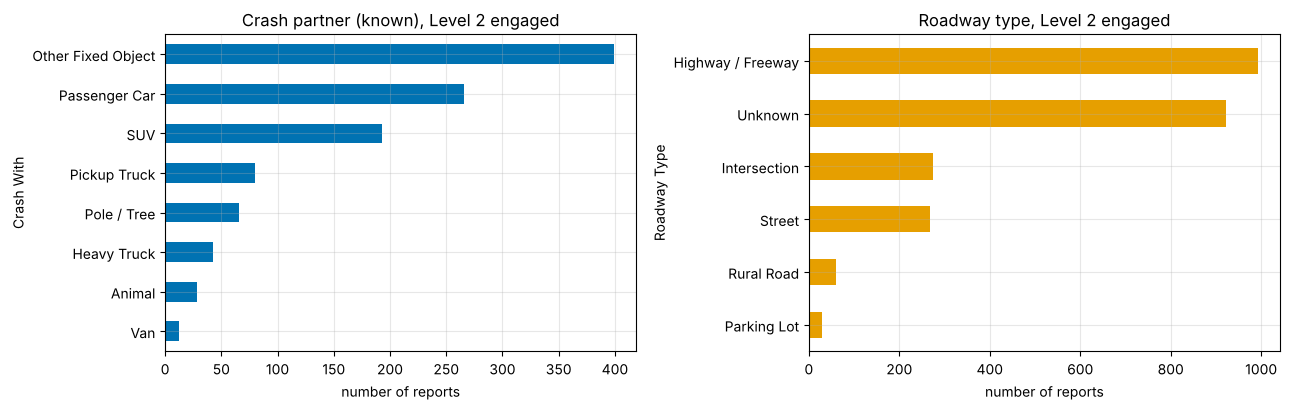

Caveats: reports are not rates (no exposure); severity is 'Unknown' in 89% of engaged reports; reporting depends on each manufacturer's telematics, so makes are not comparable.


In [4]:
try:
    sgo = D.nhtsa_sgo("ADAS")
except D.DataUnavailable as exc:
    sgo = None
    print(f"SGO data unavailable ({exc}); skipping this cell.")

if sgo is not None:
    eng = sgo[sgo["Engagement Status"].isin(["Verified Engaged", "Alleged Engaged"])].copy()
    when = pd.to_datetime(eng["Incident Date"], format="%b-%Y", errors="coerce")
    print(f"Level 2 reports in the current SGO file: {len(sgo)}; with the system engaged (verified or alleged): "
          f"{len(eng)} ({eng['Same Incident ID'].nunique()} distinct incidents)")
    print(f"Incident months: {when.min():%b %Y} to {when.max():%b %Y}; "
          f"top reporting make: {eng['Make'].value_counts().index[0]} ({eng['Make'].value_counts().iloc[0] / len(eng):.0%})")
    known = eng[~eng["Crash With"].isin(["Unknown", "Other, see Narrative"])]
    partner = known["Crash With"].value_counts()
    fixed = partner.reindex(["Other Fixed Object", "Pole / Tree"]).fillna(0).sum()
    print(f"Reports with a known crash partner: {len(known)}; of these, fixed objects (incl. pole/tree): "
          f"{fixed:.0f} ({fixed / len(known):.0%})")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    partner.head(8).iloc[::-1].plot.barh(ax=axes[0], color=OI["blue"])
    axes[0].set_xlabel("number of reports"); axes[0].set_title("Crash partner (known), Level 2 engaged")
    road = eng["Roadway Type"].value_counts().head(6)
    road.iloc[::-1].plot.barh(ax=axes[1], color=OI["orange"])
    axes[1].set_xlabel("number of reports"); axes[1].set_title("Roadway type, Level 2 engaged")
    plt.tight_layout(); plt.show()
    unk_sev = (eng["Highest Injury Severity Alleged"] == "Unknown").mean()
    print(f"Caveats: reports are not rates (no exposure); severity is 'Unknown' in {unk_sev:.0%} of engaged reports; "
          "reporting depends on each manufacturer's telematics, so makes are not comparable.")

These counts cannot show that Level 2 is more or less safe than manual driving, and they say nothing about take-over times. They do show where to look: a large share of the reports with a known crash partner involve **objects that do not move**, the situation in which a supervising driver is the designed barrier. This is the signature of complacency that the recall above addresses.

## 4. Take-over time: what the evidence says

**Take-over time (TOT)** is the time from the take-over request (TOR, in UN R157 terms the transition demand) to the first conscious driver input (steering above a threshold, or braking). It is the most studied measure, but it is not the whole story: a takeover can be fast and still unsafe (oversteering, hard braking), so **takeover quality** needs its own measures.

- **Meta-analysis** (Zhang, de Winter, Varotto, Happee & Martens, 2019): 129 studies with SAE Level 2 automation or higher. Shorter mean TOT is associated with higher **urgency**, not using a **handheld device**, not performing a **visual non-driving task**, having **experienced** a take-over before, and an **auditory or vibrotactile** request rather than visual-only; age showed no consistent effect. The mean and standard deviation of TOT were **highly correlated**, so the mean predicts variability. Across the 520 mean (or median) TOTs extracted, mean TOT ranged from 0.69 s to 19.79 s, with an average of 2.72 s (as also restated by Liang et al., 2025).
- **Non-critical transitions** (Eriksson & Stanton, 2017): 26 drivers in a simulator at 70 mph, take-over requested without time pressure. Drivers needed between about 1.9 s and 25.7 s, much longer than in the critical-scenario literature, and a secondary task (reading) lengthened and spread the times. Lead times for planned transitions must not be copied from critical-scenario studies.

Most studies, including the three used below, are **driving-simulator** studies with **high urgency** and a fixed budget of about 7 s (Gold et al., 2013, introduced the widely used 5 s and 7 s budgets). Their numbers describe drivers who expect something to happen, in an experiment.

28 conditions from 3 studies; condition means 1.88-4.33 s, SDs 0.80-1.84 s, coefficient of variation 0.26-0.61


Mean                      SD                      CV                  
                    count  mean   min   max count  mean   min   max count  mean   min   max
Study                                                                                      
Koerber et al. 2016    12  3.18  2.41  3.70    12  1.18  0.88  1.44    12  0.38  0.26  0.49
Li et al. 2018          2  3.97  3.61  4.33     2  1.82  1.79  1.84     2  0.46  0.42  0.50
Yoon et al. 2019       14  2.19  1.88  2.56    14  1.09  0.80  1.35    14  0.50  0.42  0.61

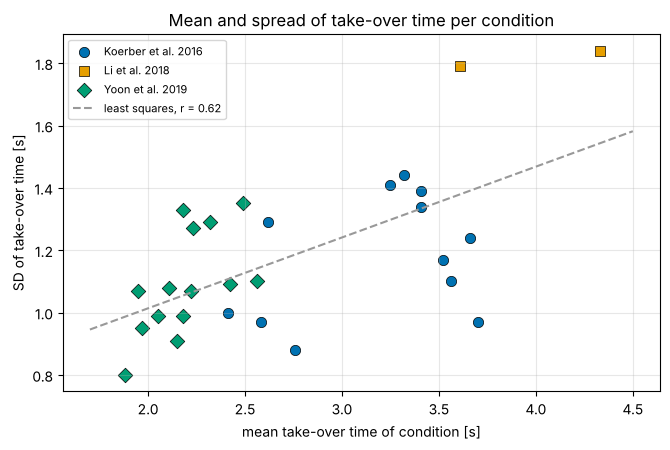

Across these 28 conditions: r(mean, SD) = 0.62 (p = 0.000); SD ~ 0.56 + 0.23 x mean.


In [5]:
# Published mean (SD) take-over times per experimental condition, as compiled in
# Liang, Calvert & van Lint (arXiv:2507.22262), Table 1, from the three primary studies.
TOT = pd.DataFrame([
    # study, age, NDRT, urgency, traffic density, TOR modality, mean [s], SD [s]
    ("Koerber et al. 2016", "young", "none", "high", "low", "A", 2.58, 0.97),
    ("Koerber et al. 2016", "young", "none", "high", "medium", "A", 3.32, 1.44),
    ("Koerber et al. 2016", "young", "none", "high", "high", "A", 3.52, 1.17),
    ("Koerber et al. 2016", "young", "phone conversation", "high", "low", "A", 2.76, 0.88),
    ("Koerber et al. 2016", "young", "phone conversation", "high", "medium", "A", 3.70, 0.97),
    ("Koerber et al. 2016", "young", "phone conversation", "high", "high", "A", 3.66, 1.24),
    ("Koerber et al. 2016", "old", "none", "high", "low", "A", 2.41, 1.00),
    ("Koerber et al. 2016", "old", "none", "high", "medium", "A", 3.41, 1.34),
    ("Koerber et al. 2016", "old", "none", "high", "high", "A", 3.41, 1.39),
    ("Koerber et al. 2016", "old", "phone conversation", "high", "low", "A", 2.62, 1.29),
    ("Koerber et al. 2016", "old", "phone conversation", "high", "medium", "A", 3.25, 1.41),
    ("Koerber et al. 2016", "old", "phone conversation", "high", "high", "A", 3.56, 1.10),
    ("Li et al. 2018", "young", "reading", "low", "low", "V+A", 3.61, 1.79),
    ("Li et al. 2018", "old", "reading", "low", "low", "V+A", 4.33, 1.84),
    ("Yoon et al. 2019", "all", "phone conversation", "high", "low", "V", 2.56, 1.10),
    ("Yoon et al. 2019", "all", "watching video", "high", "low", "V", 2.42, 1.09),
    ("Yoon et al. 2019", "all", "phone conversation", "high", "low", "T", 2.49, 1.35),
    ("Yoon et al. 2019", "all", "watching video", "high", "low", "T", 2.18, 1.33),
    ("Yoon et al. 2019", "all", "phone conversation", "high", "low", "A", 2.32, 1.29),
    ("Yoon et al. 2019", "all", "watching video", "high", "low", "A", 2.23, 1.27),
    ("Yoon et al. 2019", "all", "phone conversation", "high", "low", "V+T", 2.15, 0.91),
    ("Yoon et al. 2019", "all", "watching video", "high", "low", "V+T", 1.88, 0.80),
    ("Yoon et al. 2019", "all", "phone conversation", "high", "low", "T+A", 2.18, 0.99),
    ("Yoon et al. 2019", "all", "watching video", "high", "low", "T+A", 2.05, 0.99),
    ("Yoon et al. 2019", "all", "phone conversation", "high", "low", "V+A", 2.11, 1.08),
    ("Yoon et al. 2019", "all", "watching video", "high", "low", "V+A", 1.97, 0.95),
    ("Yoon et al. 2019", "all", "phone conversation", "high", "low", "V+T+A", 2.22, 1.07),
    ("Yoon et al. 2019", "all", "watching video", "high", "low", "V+T+A", 1.95, 1.07),
], columns=["Study", "Age", "NDRT", "Urgency", "Traffic", "TOR modality", "Mean", "SD"])
TOT["CV"] = TOT["SD"] / TOT["Mean"]
print(f"{len(TOT)} conditions from {TOT.Study.nunique()} studies; condition means {TOT.Mean.min():.2f}-{TOT.Mean.max():.2f} s, "
      f"SDs {TOT.SD.min():.2f}-{TOT.SD.max():.2f} s, coefficient of variation {TOT.CV.min():.2f}-{TOT.CV.max():.2f}")
display(TOT.groupby("Study")[["Mean", "SD", "CV"]].agg(["count", "mean", "min", "max"]).round(2))

r, p = stats.pearsonr(TOT.Mean, TOT.SD)
slope, intercept = np.polyfit(TOT.Mean, TOT.SD, 1)
fig, ax = plt.subplots(figsize=(6.8, 4.6))
for (study, g), m, col in zip(TOT.groupby("Study"), "osD", [OI["blue"], OI["orange"], OI["green"]]):
    ax.scatter(g.Mean, g.SD, marker=m, s=55, color=col, label=study, edgecolor="black", lw=0.5)
xx = np.linspace(1.7, 4.5, 50)
ax.plot(xx, intercept + slope * xx, color=OI["grey"], ls="--", label=f"least squares, r = {r:.2f}")
ax.set_xlabel("mean take-over time of condition [s]"); ax.set_ylabel("SD of take-over time [s]")
ax.set_title("Mean and spread of take-over time per condition"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"Across these 28 conditions: r(mean, SD) = {r:.2f} (p = {p:.3f}); SD ~ {intercept:.2f} + {slope:.2f} x mean.")

Even within this small set, which covers a narrow range of means (about 1.9 s to 4.3 s), mean and SD are clearly positively correlated, consistent with the meta-analysis. The practical lesson: **a condition with a longer mean also has a wider spread**, so lead times must be read from the tail, not from the mean.

## 5. A take-over-time model from published summary statistics

TOT distributions are right-skewed (Zhang et al., 2019; Eriksson & Stanton, 2017). We model each condition $i$ with a **log-normal** distribution whose mean $m_i$ and standard deviation $s_i$ match the published values (method of moments):

$$\sigma_i^2 = \ln\!\left(1 + \frac{s_i^2}{m_i^2}\right), \qquad \mu_i = \ln m_i - \tfrac{1}{2}\sigma_i^2, \qquad \text{TOT}_i \sim \text{LogNormal}(\mu_i, \sigma_i).$$

The **population** of drivers and situations is a mixture with equal weight per condition, $F(t) = \tfrac{1}{n}\sum_i F_i(t)$. The required lead time for a success probability $q$ solves $F(L_q) = q$.

> **Model assumptions:** the log-normal shape is assumed, not given by the papers; only means and SDs are published. Section 5.2 checks the sensitivity to this choice with a gamma distribution.

In [6]:
def lognormal_params(mean, sd):
    s2 = np.log1p((np.asarray(sd) / np.asarray(mean)) ** 2)
    return np.log(mean) - s2 / 2, np.sqrt(s2)

def gamma_params(mean, sd):
    k = (np.asarray(mean) / np.asarray(sd)) ** 2
    return k, np.asarray(sd) ** 2 / np.asarray(mean)          # shape, scale

TOT["mu"], TOT["sigma"] = lognormal_params(TOT.Mean, TOT.SD)
TOT["P95 (s)"] = np.exp(TOT.mu + stats.norm.ppf(0.95) * TOT.sigma)
TOT["P99 (s)"] = np.exp(TOT.mu + stats.norm.ppf(0.99) * TOT.sigma)

def mixture_cdf(t, df, family="lognormal"):
    t = np.atleast_1d(t)[:, None]
    if family == "lognormal":
        return stats.lognorm.cdf(t, s=df.sigma.values, scale=np.exp(df.mu.values)).mean(axis=1)
    k, th = gamma_params(df.Mean.values, df.SD.values)
    return stats.gamma.cdf(t, a=k, scale=th).mean(axis=1)

def required_lead_time(q, df, family="lognormal"):
    return brentq(lambda L: mixture_cdf(L, df, family)[0] - q, 0.01, 60.0)

L95, L99 = required_lead_time(0.95, TOT), required_lead_time(0.99, TOT)
print(f"Pooled population (28 conditions): median {required_lead_time(0.5, TOT):.2f} s, "
      f"L95 = {L95:.2f} s, L99 = {L99:.2f} s")
worst = TOT.loc[TOT["P95 (s)"].idxmax()]
print(f"Slowest condition by 95th percentile: {worst.Study}, {worst.Age}, {worst.NDRT}, TOR {worst['TOR modality']}: "
      f"P95 = {worst['P95 (s)']:.2f} s, P99 = {worst['P99 (s)']:.2f} s")
display(TOT.sort_values("P95 (s)", ascending=False)[["Study", "Age", "NDRT", "TOR modality", "Mean", "SD",
                                                      "P95 (s)", "P99 (s)"]].head(6).round(2))

Pooled population (28 conditions): median 2.49 s, L95 = 5.30 s, L99 = 7.20 s
Slowest condition by 95th percentile: Li et al. 2018, old, reading, TOR V+A: P95 = 7.79 s, P99 = 10.28 s


,Study,Age,NDRT,TOR modality,Mean,SD,P95 (s),P99 (s)
13,Li et al. 2018,old,reading,V+A,4.33,1.84,7.79,10.28
12,Li et al. 2018,young,reading,V+A,3.61,1.79,6.99,9.63
1,Koerber et al. 2016,young,none,A,3.32,1.44,6.03,8.00
8,Koerber et al. 2016,old,none,A,3.41,1.39,6.02,7.86
5,Koerber et al. 2016,young,phone conversation,A,3.66,1.24,5.96,7.46
7,Koerber et al. 2016,old,none,A,3.41,1.34,5.92,7.66


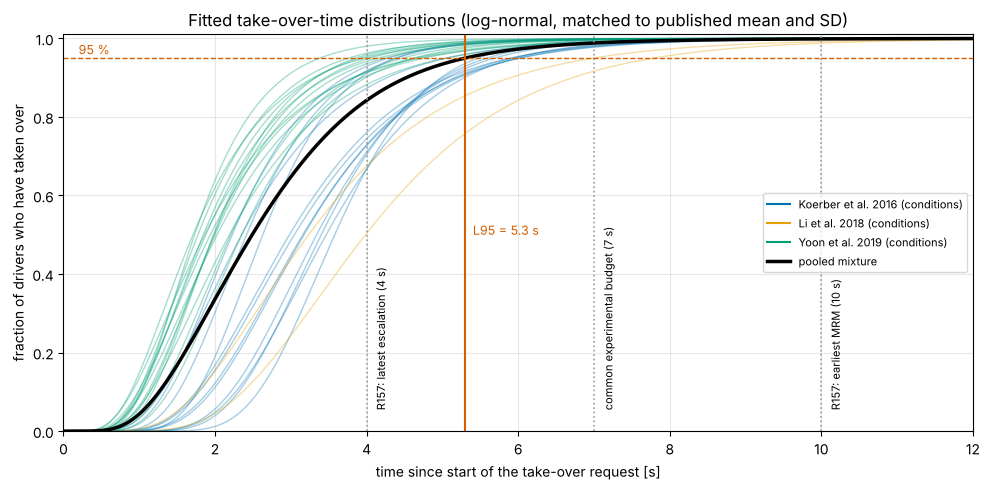

P(take-over not yet completed after  4 s) = 0.1577
P(take-over not yet completed after  7 s) = 0.0118
P(take-over not yet completed after 10 s) = 0.0013


In [7]:
t = np.linspace(0, 12, 600)
fig, ax = plt.subplots(figsize=(10, 5))
for study, col in zip(TOT.Study.unique(), [OI["blue"], OI["orange"], OI["green"]]):
    for _, row in TOT[TOT.Study == study].iterrows():
        ax.plot(t, stats.lognorm.cdf(t, s=row.sigma, scale=np.exp(row.mu)), color=col, alpha=0.35, lw=1)
    ax.plot([], [], color=col, label=f"{study} (conditions)")
ax.plot(t, mixture_cdf(t, TOT), color=OI["black"], lw=2.5, label="pooled mixture")
for x, lab in [(4, "R157: latest escalation (4 s)"), (7, "common experimental budget (7 s)"),
               (10, "R157: earliest MRM (10 s)")]:
    ax.axvline(x, color=OI["grey"], ls=":", lw=1.2); ax.text(x + 0.1, 0.06, lab, rotation=90, fontsize=8)
ax.axhline(0.95, color=OI["red"], ls="--", lw=1); ax.text(0.2, 0.96, "95 %", color=OI["red"], fontsize=9)
ax.axvline(L95, color=OI["red"], lw=1.5); ax.text(L95 + 0.1, 0.5, f"L95 = {L95:.1f} s", color=OI["red"], fontsize=9)
ax.set_xlabel("time since start of the take-over request [s]"); ax.set_ylabel("fraction of drivers who have taken over")
ax.set_title("Fitted take-over-time distributions (log-normal, matched to published mean and SD)")
ax.legend(loc="center right", fontsize=8); ax.set_xlim(0, 12); ax.set_ylim(0, 1.01)
plt.tight_layout(); plt.show()
for x in (4, 7, 10):
    print(f"P(take-over not yet completed after {x:>2} s) = {1 - mixture_cdf(x, TOT)[0]:.4f}")

### 5.1 Exercise: the lead time for 95 % successful takeovers, with its uncertainty

The point estimate $L_{95}$ hides two kinds of uncertainty: **which conditions** are represented (28 conditions from only three studies), and **which distribution shape** is right. We bootstrap over conditions and repeat the calculation with a gamma model.

L95, pooled log-normal mixture: 5.30 s; bootstrap 95 % interval over conditions: [4.87, 5.74] s
L95 with a gamma model instead: 5.29 s (shape sensitivity -0.01 s)
  L95 for Koerber et al. 2016 alone: 5.52 s
  L95 for Li et al. 2018 alone: 7.45 s
  L95 for Yoon et al. 2019 alone: 4.29 s
L99 (log-normal): 7.20 s; L99 (gamma): 6.93 s


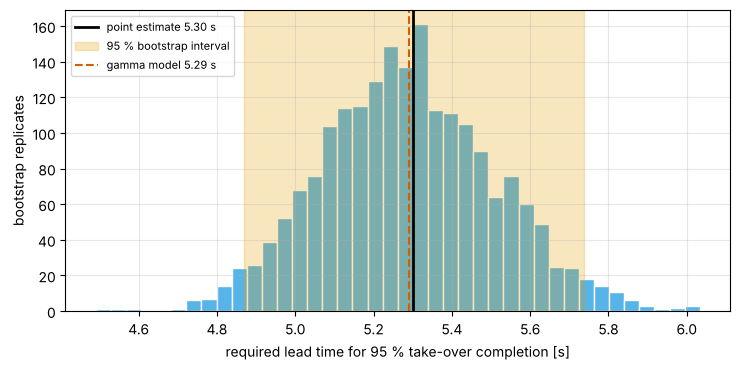

In [8]:
B = 2000
boot = np.array([required_lead_time(0.95, TOT.iloc[rng.integers(0, len(TOT), len(TOT))]) for _ in range(B)])
lo, hi = np.percentile(boot, [2.5, 97.5])
L95_gamma = required_lead_time(0.95, TOT, "gamma")
by_study = {s: required_lead_time(0.95, g) for s, g in TOT.groupby("Study")}

print(f"L95, pooled log-normal mixture: {L95:.2f} s; bootstrap 95 % interval over conditions: [{lo:.2f}, {hi:.2f}] s")
print(f"L95 with a gamma model instead: {L95_gamma:.2f} s (shape sensitivity {L95_gamma - L95:+.2f} s)")
for s, v in by_study.items():
    print(f"  L95 for {s} alone: {v:.2f} s")
print(f"L99 (log-normal): {L99:.2f} s; L99 (gamma): {required_lead_time(0.99, TOT, 'gamma'):.2f} s")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(boot, bins=40, color=OI["sky"], edgecolor="white")
ax.axvline(L95, color=OI["black"], lw=2, label=f"point estimate {L95:.2f} s")
ax.axvspan(lo, hi, color=OI["orange"], alpha=0.25, label="95 % bootstrap interval")
ax.axvline(L95_gamma, color=OI["red"], ls="--", label=f"gamma model {L95_gamma:.2f} s")
ax.set_xlabel("required lead time for 95 % take-over completion [s]"); ax.set_ylabel("bootstrap replicates")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation.** For alert, primed simulator participants with high urgency, about 95 % have made a first input within roughly 5 s, and the slowest condition (older drivers reading, visual-auditory request) needs clearly more. Three warnings before using such a number in a specification:

1. **95 % is not a safety target.** One failed takeover in twenty is far too many for a function that issues transition demands routinely. The relevant quantity is the residual risk after the system's own fallback (the MRM), which Section 6 simulates.
2. **The tail is underestimated.** These conditions come from studies with time budgets around 7 s and primed participants. Eriksson & Stanton (2017) observed up to about 25.7 s in non-critical transitions; the fitted pooled model gives that a probability of essentially zero (computed below). The model is valid only for the situations the studies represent.
3. **TOT is not takeover quality.** The first steering input is not a stabilised vehicle. Lateral and longitudinal measures (lane excursion, maximum deceleration, time to collision) must be checked as well.

In [9]:
p_long = 1 - mixture_cdf(25.7, TOT)[0]
print(f"Fitted pooled model: P(TOT > 25.7 s) = {p_long:.1e}. Eriksson & Stanton observed such times in a "
      "26-driver non-critical study, so the model built from urgent scenarios cannot be used for planned transitions.")

Fitted pooled model: P(TOT > 25.7 s) = 3.9e-07. Eriksson & Stanton observed such times in a 26-driver non-critical study, so the model built from urgent scenarios cannot be used for planned transitions.


## 6. Takeover outcomes under the UN R157 timings

UN R157 (01 series) fixes the sequence after a transition demand (see [Notebook 07-01, Section 4](01_odd_and_runtime_monitoring.ipynb)): escalation with a haptic warning **at the latest 4 s** after the start of the TD (§5.4.3.2, §6.4.1(c)); an MRM **at the earliest 10 s** after the start of the TD if the driver does not respond (§5.4.4.1), aiming at a deceleration of **not more than 4.0 m/s²** (§5.5.1); for a **planned event**, the TD must come early enough that the MRM would stop the vehicle before the event (§5.4.2.1).

We simulate what happens for a TD issued $L$ seconds before the system limit (the end of the ODD, road works, an exit). Each simulated driver draws a condition and a TOT from the model of Section 5. To represent foreseeable misuse (Section 8), a fraction $p_{nr}$ of drivers **does not respond at all** (asleep, out of the seat).

> **Illustrative data:** $p_{nr} = 1\,\%$ is an assumption chosen to show the effect, not a measured rate.

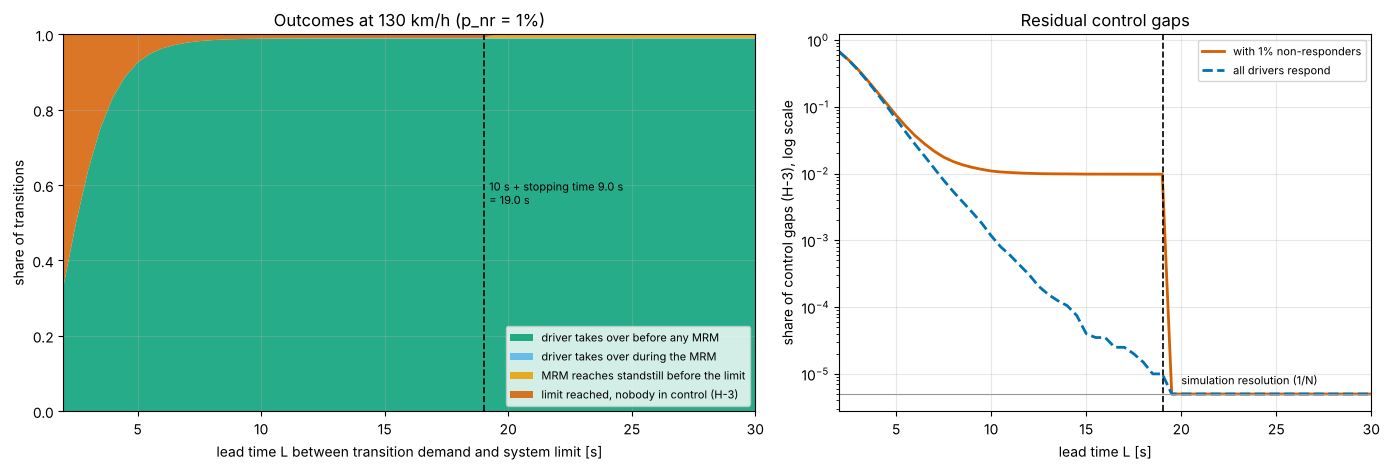

L =   5.0 s: takeover 0.925 | MRM to standstill 0.000 | control gap (H-3) 0.0746
L =   7.0 s: takeover 0.978 | MRM to standstill 0.000 | control gap (H-3) 0.0216
L =  10.0 s: takeover 0.989 | MRM to standstill 0.000 | control gap (H-3) 0.0109
L =  15.0 s: takeover 0.990 | MRM to standstill 0.000 | control gap (H-3) 0.0098
L =  19.0 s: takeover 0.990 | MRM to standstill 0.010 | control gap (H-3) 0.0000

Planned event (R157 5.4.2.1) at 130 km/h: TD at least 19.0 s, i.e. 524 m, before it.


In [10]:
V, A_MRM, T_MRM = 130 / 3.6, 4.0, 10.0          # speed [m/s], MRM deceleration [m/s^2], earliest MRM start [s]
T_STOP = V / A_MRM
P_NR = 0.01                                      # illustrative share of non-responding drivers
N = 200_000

idx = rng.integers(0, len(TOT), N)
tot0 = rng.lognormal(TOT.mu.values[idx], TOT.sigma.values[idx])   # all drivers respond
tot = tot0.copy()
tot[rng.random(N) < P_NR] = np.inf                                # with non-responders

def outcomes(L, tot):
    before_mrm = tot <= min(L, T_MRM)
    during_mrm = (tot > T_MRM) & (tot <= L)
    mrm_ok = (tot > L) & (L >= T_MRM + T_STOP)
    gap = (tot > L) & ~mrm_ok
    return np.array([before_mrm.mean(), during_mrm.mean(), mrm_ok.mean(), gap.mean()])

LS = np.arange(2, 30.5, 0.5)
res = np.array([outcomes(L, tot) for L in LS])
gap0 = np.array([outcomes(L, tot0)[3] for L in LS])
labels = ["driver takes over before any MRM", "driver takes over during the MRM",
          "MRM reaches standstill before the limit", "limit reached, nobody in control (H-3)"]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
ax.stackplot(LS, res.T, labels=labels, colors=[OI["green"], OI["sky"], OI["orange"], OI["red"]], alpha=0.85)
ax.axvline(T_MRM + T_STOP, color=OI["black"], ls="--", lw=1.2)
ax.text(T_MRM + T_STOP + 0.2, 0.55, f"10 s + stopping time {T_STOP:.1f} s\n= {T_MRM + T_STOP:.1f} s", fontsize=8)
ax.set_xlabel("lead time L between transition demand and system limit [s]")
ax.set_ylabel("share of transitions"); ax.set_ylim(0, 1); ax.set_xlim(LS[0], LS[-1])
ax.set_title(f"Outcomes at {V * 3.6:.0f} km/h (p_nr = {P_NR:.0%})")
ax.legend(loc="lower right", fontsize=8)
floor = 1 / N
ax2.semilogy(LS, np.maximum(res[:, 3], floor), color=OI["red"], lw=2, label=f"with {P_NR:.0%} non-responders")
ax2.semilogy(LS, np.maximum(gap0, floor), color=OI["blue"], lw=2, ls="--", label="all drivers respond")
ax2.axvline(T_MRM + T_STOP, color=OI["black"], ls="--", lw=1.2)
ax2.axhline(floor, color=OI["grey"], lw=0.8); ax2.text(20, floor * 1.4, "simulation resolution (1/N)", fontsize=8)
ax2.set_xlabel("lead time L [s]"); ax2.set_ylabel("share of control gaps (H-3), log scale")
ax2.set_title("Residual control gaps"); ax2.legend(fontsize=8); ax2.set_xlim(LS[0], LS[-1])
plt.tight_layout(); plt.show()

for L in (5, 7, 10, 15, T_MRM + T_STOP):
    o = outcomes(L, tot)
    print(f"L = {L:5.1f} s: takeover {o[0] + o[1]:.3f} | MRM to standstill {o[2]:.3f} | control gap (H-3) {o[3]:.4f}")
d_td = V * T_MRM + V ** 2 / (2 * A_MRM)
print(f"\nPlanned event (R157 5.4.2.1) at 130 km/h: TD at least {T_MRM + T_STOP:.1f} s, i.e. {d_td:.0f} m, before it.")

**What the simulation shows.** For lead times below about 19 s at 130 km/h, the residual share of control gaps never falls below $p_{nr}$: **no lead time protects against a driver who does not respond**. Only when the lead time also covers the MRM (10 s waiting time plus the stopping time) does the system's own fallback cover the non-responders. This is why UN R157 couples the planned-event TD to the MRM (§5.4.2.1), and why *unplanned* events, where such a lead time is impossible, carry the highest residual risk at Level 3. The dashed curve (all drivers respond) falls steeply only because it extrapolates the fitted log-normal tail, which Section 5 showed is not supported far beyond the studied conditions; treat it as optimistic. The levers are: detect unplanned events earlier, reduce speed during the transition (§5.4.3), and make sure that drivers who cannot respond are detected **before** a TD is needed (driver availability, Section 7).

## 7. Driver monitoring: what the regulations require

**UN R157 (ALKS, Level 3)**

- *Driver availability recognition* (§6.1): the system detects that the driver is in the driving position, belted and available. A TD is initiated if the driver is out of the seat for more than 1 s or unbuckles (§6.1.2). The driver is deemed **unavailable unless at least two availability criteria** (e.g. input to driver-exclusive controls, eye blinking, eye closure, conscious head or body movement) have each confirmed availability **within the last 30 s**; when the driver is deemed unavailable, a distinctive warning starts, and a TD follows at the latest after 15 s of warning (§6.1.3.1).
- *Driver attentiveness* (§6.3.1.1): gaze primarily on the road ahead or the mirrors, or head movement primarily directed to the driving task. It is used, for example, to accept a takeover during a TD (§6.2.5.2).
- Other activities on on-board displays are suspended when a TD starts (§6.1.4).

**Regulation (EU) 2019/2144 (General Safety Regulation)** requires two driver-monitoring systems in all motor vehicles of categories M and N (Art. 6(1)(c), (d); dates in Annex II):

In [11]:
gsr = pd.DataFrame([
    ("Driver drowsiness and attention warning (DDAW)", "Art. 3(5), 6(1)(c)",
     "assesses the driver's alertness through vehicle systems analysis and warns if needed",
     date(2022, 7, 6), date(2024, 7, 7), "Delegated Reg. (EU) 2021/1341"),
    ("Advanced driver distraction warning (ADDW)", "Art. 3(6), 6(1)(d)",
     "helps the driver to keep paying attention to the traffic situation and warns when distracted",
     date(2024, 7, 7), date(2026, 7, 7), "Delegated Reg. (EU) 2023/2590"),
], columns=["System", "Legal basis", "Definition (paraphrased)", "New types from", "All new registrations from",
            "Technical rules"])
gsr["Status on " + TODAY.isoformat()] = [
    "required for all new registrations" if TODAY >= r["All new registrations from"] else
    "required for new types" if TODAY >= r["New types from"] else "not yet required" for _, r in gsr.iterrows()]
display(gsr)
print("Art. 6(3): DDAW and ADDW must not continuously record or retain data beyond what the closed-loop "
      "system needs, the data must not be accessible to third parties and must be deleted after processing.")

,System,Legal basis,Definition (paraphrased),New types from,All new registrations from,Technical rules,Status on 2026-10-28
0,Driver drowsiness and attention warning (DDAW),"Art. 3(5), 6(1)(c)",assesses the driver's alertness through vehicle systems analysis and warns if needed,2022-07-06,2024-07-07,Delegated Reg. (EU) 2021/1341,required for all new registrations
1,Advanced driver distraction warning (ADDW),"Art. 3(6), 6(1)(d)",helps the driver to keep paying attention to the traffic situation and warns when distracted,2024-07-07,2026-07-07,Delegated Reg. (EU) 2023/2590,required for all new registrations


Art. 6(3): DDAW and ADDW must not continuously record or retain data beyond what the closed-loop system needs, the data must not be accessible to third parties and must be deleted after processing.


DDAW and ADDW are **warning** systems for manual and Level 2 driving; they do not by themselves make a Level 2 system safe, and they are not the availability recognition of a Level 3 ALKS. A Level 3 DMS has a harder job: it must decide whether the driver *could* take over within seconds, while the driver is legitimately not watching the road.

**Why two criteria? A dependent-failure view.** R157 asks for two availability criteria. If each criterion wrongly reports "available" for a sleeping driver with probability $p$, two independent criteria fail together with probability $p^2$. Criteria that share a cause (both use the same eye camera; sunglasses defeat both) do not achieve this. With the beta-factor model of [Notebook 03-04](../03_Functional_Safety_ISO26262/04_fault_tree_analysis.ipynb), a fraction $\beta$ of each criterion's false "available" verdicts is common to both:

> **Illustrative data:** $p$ and $\beta$ are assumptions for the calculation, not measured DMS performance.

In [12]:
p = 0.05
for beta in (0.0, 0.1, 0.3, 0.6):
    both = beta * p + ((1 - beta) * p) ** 2
    print(f"beta = {beta:.1f}: P(both criteria wrongly report 'available') = {both:.4f} "
          f"({both / p**2:.1f} x the independent value {p**2:.4f})")
print("Diverse criteria (e.g. eye closure from a camera AND a driver-exclusive control input) keep beta small.")

beta = 0.0: P(both criteria wrongly report 'available') = 0.0025 (1.0 x the independent value 0.0025)
beta = 0.1: P(both criteria wrongly report 'available') = 0.0070 (2.8 x the independent value 0.0025)
beta = 0.3: P(both criteria wrongly report 'available') = 0.0162 (6.5 x the independent value 0.0025)
beta = 0.6: P(both criteria wrongly report 'available') = 0.0304 (12.2 x the independent value 0.0025)
Diverse criteria (e.g. eye closure from a camera AND a driver-exclusive control input) keep beta small.


## 8. Foreseeable misuse as a SOTIF work product

ISO 21448 includes **reasonably foreseeable misuse** in the scope of SOTIF: hazards can result from the driver using the system in a way not intended by the manufacturer but predictable from human behaviour, without any fault. UN R157 makes this explicit for ALKS: the manufacturer shall take measures to guard against reasonably foreseeable misuse by the driver and tampering (§5.1.8), and the Annex 4 safety-concept audit checks foreseeable misuse, driver mistakes such as unintentional override, and tampering (Annex 4, §3.4.4(vi)).

Patel & Jung (2023) and Patel, Jung & Cakir (2023) describe a **simulation-based** process for this: derive potential misuse scenarios from the system design and expected driver behaviour, test them with drivers in a **driving simulator**, define evaluation criteria in line with ISO 21448 for the measures that prevent or mitigate the misuse, and evaluate the measures' effectiveness; the driver-vehicle interface is the central element, because unambiguous information on system functions and states lets the driver perceive, comprehend and act correctly.

The worksheet below is the core of such an analysis. Each row needs evidence that the misuse is foreseeable, a link to a hazard of the [STPA](../03_Functional_Safety_ISO26262/05_stpa.ipynb), a measure and a verification method.

> **Illustrative data:** a teaching worksheet for a generic ALKS and Level 2 system, not the analysis of a real product.

In [13]:
misuse = pd.DataFrame([
    ("MU-1", "L3", "Activating the ALKS outside its ODD (e.g. on a road without physical separation)",
     "Drivers test system limits", "H-3",
     "Activation only if all R157 6.2.3 conditions hold (incl. road type (g)); clear denial message (6.4.2.1)",
     "Activation-denial tests at every ODD boundary"),
    ("MU-2", "L3", "Sleeping or prolonged eye closure while the ALKS drives",
     "Long monotonous motorway trips; R157 6.1.3 exists for this", "H-3, H-4",
     "Two diverse availability criteria within 30 s; warning, TD after <= 15 s; MRM",
     "Driving-simulator study with drowsy participants; DMS validation set incl. eyewear"),
    ("MU-3", "L3", "Leaving the driver seat or unbuckling during ALKS operation",
     "Reaching for objects in the rear", "H-3",
     "TD if out of seat > 1 s or belt unbuckled (6.1.2); seat and belt plausibility",
     "Tests incl. belt buckled behind the occupant"),
    ("MU-4", "L2", "Defeating hands-on detection (steering-wheel weights) or the camera",
     "Defeat devices are sold commercially", "H-1, H-2",
     "Camera-based DMS with gaze and liveness checks; torque-pattern plausibility",
     "Defeat-device test catalogue; field monitoring of anomalies"),
    ("MU-5", "L2", "Treating Level 2 as Level 3: phone in hand, eyes off road",
     "Complacency with reliable automation; recall 23V-838 and RQ24-009", "H-1, H-2",
     "ADDW/DMS escalation, feature lockout after repeated warnings, HMI naming and user information",
     "Naturalistic or field data on warning rates and responses"),
    ("MU-6", "L3", "Using a handheld phone as the non-driving task during ALKS operation",
     "Only on-board displays are suspended at a TD (R157 6.1.4)", "H-3",
     "Lead time sized for handheld-device conditions; encourage integrated displays",
     "Take-over study with a handheld task (handheld use lengthens TOT: Zhang et al., 2019)"),
    ("MU-7", "L3", "Ignoring transition demands, relying on the MRM",
     "Learned behaviour after harmless MRMs", "H-4",
     "Reactivation only after a new engine cycle after an MRM (R157 5.5.5); escalating consequences",
     "Simulator study of repeated TDs; DSSAD analysis in the field"),
], columns=["ID", "Level", "Misuse", "Why foreseeable (evidence)", "STPA hazard", "Measure", "Verification"])
assert misuse[["Measure", "Verification", "Why foreseeable (evidence)"]].apply(lambda c: c.str.len() > 0).all().all()
display(misuse)
print(misuse.groupby("Level").size().rename("misuse cases per level").to_string())
print("Every misuse case has evidence of foreseeability, a measure and a verification method.")

,ID,Level,Misuse,Why foreseeable (evidence),STPA hazard,Measure,Verification
0,MU-1,L3,Activating the ALKS outside its ODD (e.g. on a road without physical separation),Drivers test system limits,H-3,Activation only if all R157 6.2.3 conditions hold (incl. road type (g)); clear denial message (6...,Activation-denial tests at every ODD boundary
1,MU-2,L3,Sleeping or prolonged eye closure while the ALKS drives,Long monotonous motorway trips; R157 6.1.3 exists for this,"H-3, H-4","Two diverse availability criteria within 30 s; warning, TD after <= 15 s; MRM",Driving-simulator study with drowsy participants; DMS validation set incl. eyewear
2,MU-3,L3,Leaving the driver seat or unbuckling during ALKS operation,Reaching for objects in the rear,H-3,TD if out of seat > 1 s or belt unbuckled (6.1.2); seat and belt plausibility,Tests incl. belt buckled behind the occupant
3,MU-4,L2,Defeating hands-on detection (steering-wheel weights) or the camera,Defeat devices are sold commercially,"H-1, H-2",Camera-based DMS with gaze and liveness checks; torque-pattern plausibility,Defeat-device test catalogue; field monitoring of anomalies
4,MU-5,L2,"Treating Level 2 as Level 3: phone in hand, eyes off road",Complacency with reliable automation; recall 23V-838 and RQ24-009,"H-1, H-2","ADDW/DMS escalation, feature lockout after repeated warnings, HMI naming and user information",Naturalistic or field data on warning rates and responses
5,MU-6,L3,Using a handheld phone as the non-driving task during ALKS operation,Only on-board displays are suspended at a TD (R157 6.1.4),H-3,Lead time sized for handheld-device conditions; encourage integrated displays,"Take-over study with a handheld task (handheld use lengthens TOT: Zhang et al., 2019)"
6,MU-7,L3,"Ignoring transition demands, relying on the MRM",Learned behaviour after harmless MRMs,H-4,Reactivation only after a new engine cycle after an MRM (R157 5.5.5); escalating consequences,Simulator study of repeated TDs; DSSAD analysis in the field


Level
L2    2
L3    5
Every misuse case has evidence of foreseeability, a measure and a verification method.


## 9. Exercise

1. The slowest condition in the data is older drivers reading with a visual-auditory request (Li et al., 2018). Compute its 95th and 99th percentile, and the lead time for 99 % takeovers in the pooled population.
2. Suppose a real-car study found the spread of TOT to be 30 % larger than in the simulator (same means). How much does $L_{95}$ of the pooled population change?
3. Using the simulation of Section 6, find the smallest lead time at 100 km/h above which the share of control gaps is below 0.1 % for $p_{nr} = 1\,\%$.

In [14]:
# Exercise scaffold (runs as is; complete the TODOs)
slow = TOT[(TOT.Study == "Li et al. 2018") & (TOT.Age == "old")].iloc[0]
print(f"Condition: {slow.Study}, {slow.Age}, {slow.NDRT}: mean {slow.Mean} s, SD {slow.SD} s")
# TODO 1: P95 and P99 of this condition; required_lead_time(0.99, TOT)
# TODO 2: wider = TOT.assign(SD=1.3 * TOT.SD); recompute mu, sigma and required_lead_time(0.95, wider)
# TODO 3: repeat the outcome simulation with V = 100 / 3.6

Condition: Li et al. 2018, old, reading: mean 4.33 s, SD 1.84 s


<details>
<summary>Solution</summary>

```python
# 1.
print(slow["P95 (s)"], slow["P99 (s)"], required_lead_time(0.99, TOT))
# 2.
wider = TOT.assign(SD=1.3 * TOT.SD)
wider["mu"], wider["sigma"] = lognormal_params(wider.Mean, wider.SD)
print(required_lead_time(0.95, wider) - L95)
# 3.
V100 = 100 / 3.6
t_stop = V100 / A_MRM
gap = lambda L: ((tot > L) & (L < T_MRM + t_stop)).mean()
print(next(L for L in np.arange(2, 40, 0.1) if gap(L) < 1e-3))
```

1. About 7.8 s (P95) and 10.3 s (P99) for this condition, against a pooled $L_{99}$ of about 7.2 s. A slow population (older drivers with a visual task) can need about one and a half times the pooled lead time, and its 99th percentile already exceeds the 10 s after which an R157 MRM may start.
2. $L_{95}$ grows by about 0.6 s (from about 5.3 s to 5.9 s): the tail scales with the spread, which is why the mean-SD correlation matters.
3. Just above $10 + 27.8/4.0 \approx 16.9$ s: below that, the non-responders alone keep the gap share at 1 %. The answer is set by the MRM, not by the attentive drivers.
</details>

## In industry

**Work products fed.** The **HMI specification** (transition demand signals, escalation, mode indications) and the **driver-monitoring requirements** (availability and attentiveness criteria, time windows, validation targets) of a Level 3 system; the **foreseeable-misuse analysis** and the corresponding acceptance criteria and verification results in the ISO 21448 documentation; controllability evidence for the HARA (ISO 26262-3, C ratings for driver-assistance functions); for UN R157 the Annex 4 documentation of misuse handling and the justification of the availability criteria (§6.1.3.1 requires documented evidence for their number and combination); for Level 2 in the EU the DDAW/ADDW type-approval documentation under Regulation (EU) 2019/2144.

**Owner.** A human-factors engineering team owns the take-over and misuse studies and the HMI concept; the DMS team owns the classifier and its validation; the SOTIF or system safety engineer owns the requirement that links lead times, DMS performance and MRM capability; homologation engineers own the R157 and GSR evidence.

**Tools and formats.** Driving simulators and test-track studies with documented protocols (participants, NDRT, urgency, budget, measures), ideally reporting full TOT distributions or percentiles, not only means; take-over quality measures alongside TOT; DMS validation datasets covering eyewear, lighting, occlusion and demographics; field data from DSSAD and fleet monitoring (rates of TDs, MRMs, warnings and responses), which feed back into the misuse analysis.

**Typical review findings**
- Lead time justified with a *mean* take-over time from one study, or with a budget of 7 s copied from the literature.
- Simulator results with primed, high-urgency participants used for planned, non-critical transitions.
- Take-over time reported, take-over quality not.
- Availability criteria that share one sensor, so the "two criteria" do not fail independently.
- Misuse analysis limited to the owner's manual; no simulator or field evidence that measures work; repeated-misuse behaviour (learning to game warnings) not considered.
- Mode transitions with optical-only feedback; no hands-off check after deactivation.

**What an assessor checks:** the TD timing traced to take-over evidence with the population, NDRT and urgency stated, and to the MRM timing of R157; DMS criteria, thresholds and time windows justified with documented evidence; foreseeable misuse identified systematically with measures verified by tests with drivers; field monitoring with defined indicators (TD response times, MRM rate, misuse warnings) and triggers for updating the analysis.

## Key takeaways

1. **Level 2 and Level 3 put the human in different places.** At Level 2 the driver supervises continuously; at Level 3 the fallback-ready user must re-enter the loop after a transition demand. The monitoring problem differs accordingly: engagement versus availability.
2. **Complacency, mode confusion and out-of-the-loop** are predictable consequences of good automation, not driver faults; the NHTSA recall 23V-838 names all three.
3. **Take-over times are right-skewed, and spread grows with the mean.** Zhang et al. (2019) found mean TOT associated with urgency, handheld devices, visual tasks, prior experience and request modality; non-critical transitions take much longer (Eriksson & Stanton, 2017).
4. **Specify lead times from the tail, with uncertainty.** From published summary statistics, about 95 % of primed simulator drivers respond within roughly 5 s (pooled; bootstrap interval about ±0.5 s), but the single studies range from about 4.3 s to 7.5 s, and slow populations and non-critical transitions need much more.
5. **No lead time protects against a non-responding driver.** Only the MRM does; UN R157 couples planned-event TDs to the MRM (10 s plus stopping time), and unplanned events carry the highest residual risk.
6. **Driver monitoring and misuse analysis are safety work products**, with regulatory hooks: R157 §6.1 (two criteria within 30 s), §5.1.8 and Annex 4 (foreseeable misuse), and DDAW/ADDW under Regulation (EU) 2019/2144.

## Self-assessment

1. What is the difference between the Level 2 driver and the Level 3 fallback-ready user in SAE J3016?
2. Why does reliable automation increase the risk of complacency?
3. Name four determinants of take-over time found by Zhang et al. (2019).
4. Why must lead times not be specified from the mean take-over time?
5. Why does no lead time below about 19 s at 130 km/h bring the control-gap share below $p_{nr}$ in Section 6?
6. State the UN R157 driver-availability rule and explain the role of two criteria.
7. Give two examples of foreseeable misuse for a Level 3 system, with a measure and a verification method for each.

<details>
<summary>Answers</summary>

1. The Level 2 driver performs part of the DDT (the remaining OEDR) and supervises the system at all times. The Level 3 fallback-ready user does not perform the DDT while the ADS is engaged, but must be able to operate the vehicle and be receptive to requests to intervene and to evident vehicle system failures.
2. When failures are rare, attention to the automation is allocated elsewhere; the human samples less and accepts its outputs, so the rare failure is missed (Parasuraman & Manzey, 2010).
3. Urgency (time budget), handheld device use, visual non-driving task, prior experience with a take-over, and request modality (auditory or vibrotactile faster than visual-only); age showed no consistent effect.
4. The distribution is right-skewed and its spread grows with the mean; the mean leaves about half of the drivers too slow. Lead times must come from high percentiles, with uncertainty, for the population and task that apply.
5. Non-responding drivers never take over; for them, only an MRM that reaches standstill before the limit helps, which needs 10 s (earliest MRM start) plus the stopping time at 4 m/s² (about 9 s from 130 km/h).
6. The driver is deemed unavailable unless at least two availability criteria have each confirmed availability in the last 30 s; then a warning starts and a TD follows at the latest after 15 s (§6.1.3.1). Two criteria reduce the chance of a false "available" verdict, but only if they do not share a cause.
7. For example: sleeping while the ALKS drives (two diverse availability criteria, warning and TD, MRM; verified in a simulator study with drowsy participants and a DMS validation set); leaving the seat (TD after 1 s out of seat or unbuckling; verified with seat and belt tests including defeat attempts); ignoring TDs and relying on the MRM (no reactivation before a new engine cycle; verified in a simulator study of repeated TDs).
</details>

## References

1. SAE International (2021). *J3016_202104: Taxonomy and Definitions for Terms Related to Driving Automation Systems for On-Road Motor Vehicles*. https://www.sae.org/standards/content/j3016_202104/
2. Bainbridge, L. (1983). Ironies of automation. *Automatica*, 19(6), 775–779. https://doi.org/10.1016/0005-1098(83)90046-8
3. Parasuraman, R., & Manzey, D. H. (2010). Complacency and bias in human use of automation: An attentional integration. *Human Factors*, 52(3), 381–410. https://doi.org/10.1177/0018720810376055
4. Sarter, N. B., & Woods, D. D. (1995). How in the world did we ever get into that mode? Mode error and awareness in supervisory control. *Human Factors*, 37(1), 5–19. https://doi.org/10.1518/001872095779049516
5. Endsley, M. R., & Kiris, E. O. (1995). The out-of-the-loop performance problem and level of control in automation. *Human Factors*, 37(2), 381–394. https://doi.org/10.1518/001872095779064555
6. Zhang, B., de Winter, J., Varotto, S., Happee, R., & Martens, M. (2019). Determinants of take-over time from automated driving: A meta-analysis of 129 studies. *Transportation Research Part F*, 64, 285–307. https://doi.org/10.1016/j.trf.2019.04.020 (supplementary data, CC0: https://doi.org/10.4121/uuid:75c28abe-6559-4273-85f4-927e969c1c59)
7. Eriksson, A., & Stanton, N. A. (2017). Takeover time in highly automated vehicles: Noncritical transitions to and from manual control. *Human Factors*, 59(4), 689–705. https://doi.org/10.1177/0018720816685832 (range 1.9–25.7 s as reported by the University of Southampton, January 2017: https://www.southampton.ac.uk/engineering/news/2017/01/takeover-time-in-driverless-cars.page)
8. Gold, C., Damböck, D., Lorenz, L., & Bengler, K. (2013). "Take over!" How long does it take to get the driver back into the loop? *Proceedings of the HFES Annual Meeting*, 57(1), 1938–1942. https://doi.org/10.1177/1541931213571433
9. Liang, K., Calvert, S. C., & van Lint, J. W. C. (2025). Towards safe and comfortable vehicle control transitions: A systematic review of takeover time, time budget, and takeover performance. arXiv:2507.22262 (Table 1 used here). https://arxiv.org/abs/2507.22262 Published version: *Human Factors*, 68(11), 1471–1499 (2026). https://doi.org/10.1177/00187208261456057
10. Körber, M., Gold, C., Lechner, D., & Bengler, K. (2016). The influence of age on the take-over of vehicle control in highly automated driving. *Transportation Research Part F*, 39, 19–32. https://doi.org/10.1016/j.trf.2016.03.002
11. Li, S., Blythe, P., Guo, W., & Namdeo, A. (2018). Investigation of older driver's takeover performance in highly automated vehicles in adverse weather conditions. *IET Intelligent Transport Systems*, 12(9), 1157–1165. https://doi.org/10.1049/iet-its.2018.0104
12. Yoon, S. H., Kim, Y. W., & Ji, Y. G. (2019). The effects of takeover request modalities on highly automated car control transitions. *Accident Analysis & Prevention*, 123, 150–158. https://doi.org/10.1016/j.aap.2018.11.018
13. UNECE (2023). UN Regulation No. 157 — Automated Lane Keeping Systems, 01 series of amendments, E/ECE/TRANS/505/Rev.3/Add.156/Amend.4 (paragraphs 5.1.8, 5.4, 5.5, 6.1–6.4; Annex 4 §3.4.4). Copy consulted: https://www.marklines.com/statics/unece/pdf_202311/R157am4e.pdf
14. Regulation (EU) 2019/2144 of the European Parliament and of the Council (General Safety Regulation), OJ L 325, 16.12.2019 (Art. 3(5)–(6), Art. 6, Annex II). https://eur-lex.europa.eu/eli/reg/2019/2144/oj ; Commission Delegated Regulations (EU) 2021/1341 (DDAW) https://eur-lex.europa.eu/eli/reg_del/2021/1341/oj and (EU) 2023/2590 (ADDW) https://eur-lex.europa.eu/eli/reg_del/2023/2590/oj
15. NHTSA (2023). Recall 23V-838 (Tesla Autosteer), report received 12 December 2023. https://www.nhtsa.gov/recalls?nhtsaId=23V838 ; NHTSA (2024). Recall Query RQ24-009, opening résumé, 25 April 2024. https://static.nhtsa.gov/odi/inv/2024/INOA-RQ24009-12046.pdf
16. NHTSA. Standing General Order 2021-01, crash reporting (Level 2 ADAS incident reports). https://www.nhtsa.gov/laws-regulations/standing-general-order-crash-reporting
17. ISO 21448:2022. *Road vehicles — Safety of the intended functionality*. https://www.iso.org/standard/77490.html
18. Patel, M., & Jung, R. (2023). Simulation-based application of safety of the intended functionality to mitigate foreseeable misuse in automated driving systems. SAE preprint. https://doi.org/10.47953/sae-pp-00371
19. Patel, M., Jung, R., & Cakir, Y. (2023). Simulation-based testing of foreseeable misuse by the driver applicable for highly automated driving. In *Proceedings of the Eighth International Congress on Information and Communication Technology*, LNNS, pp. 183–191. Springer. https://doi.org/10.1007/978-981-99-3043-2_15

---
**Navigation:** ← [02 Safe motion planning and fallback](02_safe_motion_planning_and_fallback.ipynb) · [Module index](README.md) · [04 V2X and cooperative driving](04_v2x_cooperative_driving.ipynb) →